# TF–DNA predictions at mouse CUT&RUN binding sites

This notebook evaluates the **mm10 TF–DNA checkpoint `tf_dna_mm10_3925194/epoch_21.ckpt`** on published CUT&RUN peaks. NANOG provides a pluripotency-associated, lineage-restricted comparison, and CTCF provides a broadly binding reference. The question is whether the trained sequence model ranks experimentally bound windows above matched genomic background.

Run every code cell on an HPC **compute node**, including notebook execution. No model fitting or threshold tuning is performed here. Primary analyses use **chr18 and chr19**, conditional on an audit of the existing saved training and validation splits. The checkpoint and persisted training data are read without modifying or resampling them.


In [1]:
from pathlib import Path
import os
import socket
import sys

# Stop before importing scientific packages if the notebook is opened on a gateway.
if "hgtw" in socket.gethostname().lower() or "gtwy" in socket.gethostname().lower():
    raise RuntimeError("Run this notebook on a Slurm compute node, as required by CLAUDE.md.")

PROJECT_DIR = Path("/gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER")
TETHER_DIR = PROJECT_DIR / "TETHER"
DATA_DIR = PROJECT_DIR / "data"
CACHED_DATA_DIR = TETHER_DIR / "cached_data"
cell_type = "mm10"
tf_dna_input_cache_dir = CACHED_DATA_DIR / cell_type / "tf_dna_cache"

# This checkout stores the requested checkpoint inside TETHER/.
tf_dna_model_path = TETHER_DIR / "checkpoints" / "tf_dna_mm10_3925194" / "epoch_21.ckpt"
cutrun_data_dir = DATA_DIR / "CUT&RUN_data"
tf_embedding_dir = DATA_DIR / "tf_data" / cell_type / "tf_embeddings"
genome_fasta_path = DATA_DIR / "genome_data" / "reference_genome" / cell_type / "mm10.fa"
evaluation_result_dir = TETHER_DIR / "new_testing_results" / "tf_dna_cutrun_epoch21"
evaluation_figure_dir = TETHER_DIR / "new_plots" / "tf_dna_cutrun_epoch21"
evaluation_result_dir.mkdir(parents=True, exist_ok=True)
evaluation_figure_dir.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(TETHER_DIR))

import bisect
import gzip
import hashlib
import json
import logging
import platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import sklearn
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager
import pysam
from IPython.display import display, Markdown
from sklearn.metrics import (
    roc_curve, precision_recall_curve, roc_auc_score,
    average_precision_score, confusion_matrix,
)
import utils
from matplotlib_inline import backend_inline
get_ipython().run_line_magic("matplotlib", "inline")
backend_inline.set_matplotlib_formats("svg")

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
RANDOM_SEED = 42
EVALUATION_CHROMOSOMES = ("chr18", "chr19")
DNA_WINDOW_LENGTH = 256
GC_MATCH_TOLERANCE = 0.02
MAXIMUM_MATCH_ATTEMPTS = 5000
INFERENCE_BATCH_SIZE = 64
BOOTSTRAP_REPLICATES = 500
torch.manual_seed(RANDOM_SEED)
torch.set_num_threads(min(4, int(os.environ.get("SLURM_CPUS_PER_TASK", "4"))))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Host: {socket.gethostname()} | device: {device}")
print(f"Checkpoint: {tf_dna_model_path}")


Host: psh01com1hdns06 | device: cuda
Checkpoint: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/checkpoints/tf_dna_mm10_3925194/epoch_21.ckpt


## Data sources and scope

| TF | GEO sample | Biological material | File and use |
|---|---|---|---|
| Nanog | [GSM5484582](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM5484582) | Mouse ES cells, before GATA6 induction, replicate 1 | Author-supplied narrowPeak |
| Nanog | [GSM5484583](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM5484583) | Same condition, replicate 2 | Author-supplied narrowPeak |
| Ctcf | [GSM7698720](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM7698720) | AgRP neurons, 3,000 nuclei | Author-filtered narrowPeak |
| Ctcf | [GSM7698722](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM7698722) | Whole cerebellum, 10,000 nuclei | Author-filtered narrowPeak |

NANOG data come from [GSE181104](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE181104) and [Thompson et al., 2022](https://doi.org/10.1038/s41467-022-31938-5), which profiles pluripotency and primitive-endoderm lineage regulators. NANOG expression is associated with the pluripotent/epiblast program rather than being ubiquitous. We use the uninduced 0-hour condition to avoid interpreting forced GATA6 expression as an endogenous NANOG state. A fifth analysis retains replicate-1 NANOG peaks that overlap replicate 2 by at least one base; this is a reproducibility filter, **not an IDR analysis**.

CTCF data come from [GSE240484](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE240484). GEO reports mm10 alignment and MACS2 peaks filtered using pseudoreplicates. The two CTCF samples are distinct biological materials, not biological replicates.

Processed peaks are downloaded rather than re-calling peaks from raw reads. Exact download commands are in `data/CUT&RUN_data/download_instructions.txt`; GEO SOFT metadata and SHA-256 checksums are retained beside the data. The [ENCODE mm10 blacklist v2](https://github.com/Boyle-Lab/Blacklist) removes problematic regions from both classes. The reference FASTA is already present locally; primary chromosome lengths are checked against [UCSC mm10](https://hgdownload.soe.ucsc.edu/goldenPath/mm10/bigZips/mm10.chrom.sizes).


In [2]:
cutrun_dataset_definitions = [
    dict(dataset="Nanog_ESC_rep1", tf_name="Nanog", accession="GSM5484582",
         series="GSE181104", filename="GSM5484582_DL_44_CR_Nanog_0h_rep1_peaks.narrowPeak.gz"),
    dict(dataset="Nanog_ESC_rep2", tf_name="Nanog", accession="GSM5484583",
         series="GSE181104", filename="GSM5484583_DL_45_CR_Nanog_0h_rep2_peaks.narrowPeak.gz"),
    dict(dataset="Ctcf_AgRP", tf_name="Ctcf", accession="GSM7698720",
         series="GSE240484", filename="GSE240484_CUT-RUN.CTCF.Mm_ARC_AgRP-pos_003K_01-1.filt.narrowPeak.gz"),
    dict(dataset="Ctcf_cerebellum", tf_name="Ctcf", accession="GSM7698722",
         series="GSE240484", filename="GSE240484_CUT-RUN.CTCF.Mm_cerebellum_010K_01-1.filt.narrowPeak.gz"),
]
required_paths = [
    tf_dna_model_path, genome_fasta_path,
    cutrun_data_dir / "mm10-blacklist.v2.bed.gz",
    cutrun_data_dir / "mm10.chrom.sizes",
    *[cutrun_data_dir / item["filename"] for item in cutrun_dataset_definitions],
    *[tf_embedding_dir / f"{name}_protein_embedding.pt" for name in ("Nanog", "Ctcf")],
]
for required_path in required_paths:
    if not required_path.is_file() or required_path.stat().st_size == 0:
        raise FileNotFoundError(required_path)

# Check sample identity and assembly from the downloaded metadata.
def read_geo_sample_metadata(series_accession):
    with gzip.open(cutrun_data_dir / f"{series_accession}_family.soft.gz", "rt") as handle:
        sample_blocks = handle.read().split("^SAMPLE = ")[1:]
    return {block.splitlines()[0].strip(): block for block in sample_blocks}

geo_metadata_by_series = {
    series: read_geo_sample_metadata(series) for series in ("GSE181104", "GSE240484")
}
for dataset_definition in cutrun_dataset_definitions:
    sample_metadata = geo_metadata_by_series[dataset_definition["series"]][dataset_definition["accession"]]
    assert "mm10" in sample_metadata, dataset_definition["accession"]
    assert dataset_definition["tf_name"].lower() in sample_metadata.lower()
    print(dataset_definition["accession"],
          next(line for line in sample_metadata.splitlines() if line.startswith("!Sample_title")))

genome_fasta = pysam.FastaFile(str(genome_fasta_path))
ucsc_chromosome_sizes = pd.read_csv(
    cutrun_data_dir / "mm10.chrom.sizes", sep="\t", header=None,
    names=["chromosome", "length"],
).set_index("chromosome")["length"].to_dict()
for chromosome in [f"chr{i}" for i in range(1, 20)]:
    assert genome_fasta.get_reference_length(chromosome) == ucsc_chromosome_sizes[chromosome]
print("Local reference lengths match UCSC mm10 for chromosomes 1–19.")


GSM5484582 !Sample_title = DL_44_CR_Nanog_0h_rep1
GSM5484583 !Sample_title = DL_45_CR_Nanog_0h_rep2
GSM7698720 !Sample_title = AgRP neurons, CTCF CUT&RUN, 3K nuclei
GSM7698722 !Sample_title = whole cerebellum, CTCF CUT&RUN, 10K nuclei
Local reference lengths match UCSC mm10 for chromosomes 1–19.


## Verify the saved chromosome splits

The current training code assigns mouse chromosomes 1–15 to training, 16–17 to validation, and 18–19 to testing. We verify this against the **persisted edge indices and peak mapping**, rather than creating new splits. The audit includes all TFs, since training on a chromosome with any TF would weaken a claim that its sequences were unseen.

This establishes separation from training and validation in the available cache. The checkpoint does not contain a cryptographic link to that cache, so it cannot by itself prove historical cache identity. Chromosomes 18–19 may overlap the model's original test examples; this is an assay-transfer evaluation on held-out chromosomes, not proof of entirely novel genomic loci or an unseen TF.


In [ ]:
# cached_peak_onehot = torch.load(
#     tf_dna_input_cache_dir / "peak_onehot_array.pt", map_location="cpu",
#     mmap=True, weights_only=True,
# )
# assert tuple(cached_peak_onehot.shape[1:]) == (DNA_WINDOW_LENGTH, 4)
# number_of_cached_peaks = len(cached_peak_onehot)
# cached_edge_peak_indices = torch.load(
#     tf_dna_input_cache_dir / "edge_peak_idx.pt", map_location="cpu",
#     mmap=True, weights_only=True,
# ).numpy()
# split_peak_membership = {}
# split_edge_counts = {}
# for split_name in ("train", "val", "test"):
#     saved_edge_indices = torch.load(
#         tf_dna_input_cache_dir / f"{split_name}_idx.pt", map_location="cpu", weights_only=True,
#     ).numpy()
#     assert saved_edge_indices.min() >= 0 and saved_edge_indices.max() < len(cached_edge_peak_indices)
#     peak_membership = np.zeros(number_of_cached_peaks, dtype=bool)
#     peak_membership[cached_edge_peak_indices[saved_edge_indices]] = True
#     split_peak_membership[split_name] = peak_membership
#     split_edge_counts[split_name] = len(saved_edge_indices)
#     del saved_edge_indices
# split_chromosomes = {name: set() for name in split_peak_membership}
# split_heldout_peak_counts = {name: 0 for name in split_peak_membership}

# # Read the large mapping in chunks; the existing tensors remain memory-mapped.
# for peak_mapping_chunk in pd.read_csv(
#     tf_dna_input_cache_dir / "peak_id_to_idx.csv", chunksize=250_000,
# ):
#     peak_indices = peak_mapping_chunk["peak_idx"].to_numpy()
#     chromosome_names = peak_mapping_chunk["peak_id"].str.split(":", n=1).str[0]
#     for split_name, membership in split_peak_membership.items():
#         selected = membership[peak_indices]
#         split_chromosomes[split_name].update(chromosome_names[selected].unique())
#         split_heldout_peak_counts[split_name] += int(
#             (selected & chromosome_names.isin(EVALUATION_CHROMOSOMES)).sum()
#         )

# split_audit_df = pd.DataFrame([
#     dict(split=split_name, edges=split_edge_counts[split_name],
#          chromosomes=",".join(sorted(split_chromosomes[split_name])),
#          peaks_on_evaluation_chromosomes=split_heldout_peak_counts[split_name])
#     for split_name in split_chromosomes
# ])
# display(split_audit_df)
# assert not set(EVALUATION_CHROMOSOMES) & split_chromosomes["train"]
# assert not set(EVALUATION_CHROMOSOMES) & split_chromosomes["val"]
# assert set(EVALUATION_CHROMOSOMES) <= split_chromosomes["test"]
# split_audit_df.to_csv(evaluation_result_dir / "saved_split_audit.tsv", sep="\t", index=False)
# del split_peak_membership, cached_edge_peak_indices, cached_peak_onehot


,split,edges,chromosomes,peaks_on_evaluation_chromosomes
0,train,11030462,"chr1,chr10,chr11,chr12,chr13,chr14,chr15,chr2,...",0
1,val,1104081,"chr16,chr17",0
2,test,816384,"chr18,chr19",604610


## Define positive and background windows

1. Parse BED/narrowPeak files as positives: 
    - Keep chr18–19, validate peak coordinates, and drop duplicate windows. 
    - Center a 256-bp window on either the summit (narrowPeak) or peak midpoing (BED). 
    - Remove windows that extend past the chromosome, remove overlapping peaks, and sequences containing anything except A/C/G/T. 

2. For each retained positive:
    - Sample a 256-bp genomic background window from the **same chromosome**, matching the peak's GC dinucleotide frequency within 0.02. 
    - Reject any background if it overlaps with a peak interval from the BED/narrowPeak file or with previously selected background windows. 

3. Save the complete table, sequences, labels, source peak coordinates, and pair identifiers **before inference**. 

Peaks are labeled as 1 if they come from the CUT&RUN data or 0 if they come from the sampled background sequence.

In [4]:
narrowpeak_columns = [
    "chromosome", "peak_start", "peak_end", "peak_name", "peak_score", "strand",
    "signal_value", "negative_log10_pvalue", "negative_log10_qvalue", "summit_offset",
]

def make_interval_lookup(interval_df):
    """Prefix maxima support overlap tests even when intervals overlap or nest."""
    lookup = {}
    for chromosome, chromosome_df in interval_df.groupby("chromosome", sort=False):
        ordered = chromosome_df.sort_values("start")
        lookup[chromosome] = (
            ordered["start"].to_numpy(dtype=np.int64),
            np.maximum.accumulate(ordered["end"].to_numpy(dtype=np.int64)),
        )
    return lookup

def interval_overlaps(lookup, chromosome, start, end):
    if chromosome not in lookup:
        return False
    starts, maximum_ends = lookup[chromosome]
    position = np.searchsorted(starts, end, side="left") - 1
    return bool(position >= 0 and maximum_ends[position] > start)

def read_cutrun_peaks(filename):
    peak_df = pd.read_csv(cutrun_data_dir / filename, sep="\t", header=None, comment="#")
    if peak_df.shape[1] != 10:
        raise ValueError(f"Expected 10 narrowPeak columns in {filename}; got {peak_df.shape[1]}")
    peak_df.columns = narrowpeak_columns
    for column in ("peak_start", "peak_end", "summit_offset"):
        peak_df[column] = pd.to_numeric(peak_df[column], errors="raise").astype(np.int64)
    return peak_df

raw_peak_tables = {
    item["dataset"]: read_cutrun_peaks(item["filename"])
    for item in cutrun_dataset_definitions
}
blacklist_df = pd.read_csv(
    cutrun_data_dir / "mm10-blacklist.v2.bed.gz", sep="\t", header=None,
    usecols=[0, 1, 2], names=["chromosome", "start", "end"],
)
blacklist_lookup = make_interval_lookup(blacklist_df)

nanog_replicate2_lookup = make_interval_lookup(
    raw_peak_tables["Nanog_ESC_rep2"].rename(columns={"peak_start": "start", "peak_end": "end"})
)
nanog_replicate1_df = raw_peak_tables["Nanog_ESC_rep1"]
replicate_supported = [
    interval_overlaps(nanog_replicate2_lookup, row.chromosome, row.peak_start, row.peak_end)
    for row in nanog_replicate1_df.itertuples(index=False)
]
raw_peak_tables["Nanog_ESC_overlap_supported"] = nanog_replicate1_df.loc[replicate_supported].copy()
cutrun_dataset_definitions.append(dict(
    dataset="Nanog_ESC_overlap_supported", tf_name="Nanog",
    accession="GSM5484582+GSM5484583", series="GSE181104",
    filename="replicate-1 peaks overlapping replicate 2",
))
target_peak_exclusion_lookup = {}
for tf_name in ("Nanog", "Ctcf"):
    target_peak_intervals = pd.concat([
        raw_peak_tables[item["dataset"]][["chromosome", "peak_start", "peak_end"]]
        for item in cutrun_dataset_definitions
        if item["tf_name"] == tf_name and item["dataset"] != "Nanog_ESC_overlap_supported"
    ], ignore_index=True).rename(columns={"peak_start": "start", "peak_end": "end"})
    target_peak_exclusion_lookup[tf_name] = make_interval_lookup(target_peak_intervals)

def is_unambiguous_dna(sequence):
    return len(sequence) == DNA_WINDOW_LENGTH and set(sequence) <= set("ACGT")

def gc_fraction(sequence):
    return (sequence.count("G") + sequence.count("C")) / len(sequence)

def make_matched_evaluation_table(dataset_definition, dataset_seed):
    dataset_name = dataset_definition["dataset"]
    tf_name = dataset_definition["tf_name"]
    raw_peak_df = raw_peak_tables[dataset_name]
    qc_counts = dict(dataset=dataset_name, tf_name=tf_name, raw_peaks=len(raw_peak_df))
    chromosome_peak_df = raw_peak_df.loc[
        raw_peak_df["chromosome"].isin(EVALUATION_CHROMOSOMES)
    ].copy()
    qc_counts["peaks_on_chr18_chr19"] = len(chromosome_peak_df)
    positive_records = []
    seen_window_coordinates = set()
    last_retained_end = {}
    for peak in chromosome_peak_df.sort_values(
        ["chromosome", "peak_start", "peak_end"], kind="stable",
    ).itertuples(index=False):
        chromosome_size = ucsc_chromosome_sizes[peak.chromosome]
        if not (0 <= peak.peak_start < peak.peak_end <= chromosome_size):
            continue
        summit_valid = 0 <= peak.summit_offset < peak.peak_end - peak.peak_start
        peak_center = (
            peak.peak_start + peak.summit_offset if summit_valid
            else (peak.peak_start + peak.peak_end) // 2
        )
        window_start = peak_center - DNA_WINDOW_LENGTH // 2
        window_end = window_start + DNA_WINDOW_LENGTH
        coordinates = (peak.chromosome, window_start, window_end)
        if window_start < 0 or window_end > chromosome_size or coordinates in seen_window_coordinates:
            continue
        if interval_overlaps(blacklist_lookup, *coordinates):
            continue
        # Sorting by window start is handled below because broad peaks can reorder summits.
        sequence = genome_fasta.fetch(*coordinates).upper()
        if not is_unambiguous_dna(sequence):
            continue
        seen_window_coordinates.add(coordinates)
        positive_records.append(dict(
            chromosome=peak.chromosome, start=window_start, end=window_end,
            peak_start=peak.peak_start, peak_end=peak.peak_end, peak_name=peak.peak_name,
            signal_value=peak.signal_value, center_method="summit" if summit_valid else "midpoint",
            sequence=sequence, gc_fraction=gc_fraction(sequence),
        ))
    positive_records.sort(key=lambda record: (record["chromosome"], record["start"], record["end"]))
    nonoverlapping_positives = []
    for record in positive_records:
        chromosome = record["chromosome"]
        if record["start"] >= last_retained_end.get(chromosome, -1):
            nonoverlapping_positives.append(record)
            last_retained_end[chromosome] = record["end"]
    qc_counts["valid_unique_windows"] = len(positive_records)
    qc_counts["nonoverlapping_positive_windows"] = len(nonoverlapping_positives)
    if not nonoverlapping_positives:
        raise ValueError(f"No eligible positive windows for {dataset_name}")
    positive_window_lookup = make_interval_lookup(pd.DataFrame(nonoverlapping_positives))
    random_generator = np.random.default_rng(dataset_seed)
    background_starts = {chromosome: [] for chromosome in EVALUATION_CHROMOSOMES}
    paired_records = []
    for positive in nonoverlapping_positives:
        chromosome = positive["chromosome"]
        selected_background = None
        for attempt in range(MAXIMUM_MATCH_ATTEMPTS):
            start = int(random_generator.integers(
                0, ucsc_chromosome_sizes[chromosome] - DNA_WINDOW_LENGTH + 1,
            ))
            end = start + DNA_WINDOW_LENGTH
            if interval_overlaps(target_peak_exclusion_lookup[tf_name], chromosome, start, end):
                continue
            if interval_overlaps(blacklist_lookup, chromosome, start, end):
                continue
            if interval_overlaps(positive_window_lookup, chromosome, start, end):
                continue
            existing_starts = background_starts[chromosome]
            insertion_position = bisect.bisect_left(existing_starts, start)
            if insertion_position > 0 and existing_starts[insertion_position - 1] + DNA_WINDOW_LENGTH > start:
                continue
            if insertion_position < len(existing_starts) and existing_starts[insertion_position] < end:
                continue
            sequence = genome_fasta.fetch(chromosome, start, end).upper()
            if not is_unambiguous_dna(sequence):
                continue
            background_gc_fraction = gc_fraction(sequence)
            if abs(background_gc_fraction - positive["gc_fraction"]) > GC_MATCH_TOLERANCE:
                continue
            bisect.insort(existing_starts, start)
            selected_background = dict(
                chromosome=chromosome, start=start, end=end,
                peak_start=-1, peak_end=-1, peak_name="matched_background",
                signal_value=np.nan, center_method="sampled",
                sequence=sequence, gc_fraction=background_gc_fraction,
            )
            break
        if selected_background is None:
            continue
        pair_id = f"{dataset_name}_pair_{len(paired_records) // 2:06d}"
        for label, record in ((1, positive), (0, selected_background)):
            paired_records.append(dict(
                dataset=dataset_name, tf_name=tf_name,
                accession=dataset_definition["accession"], pair_id=pair_id, label=label, **record,
            ))
    qc_counts["matched_pairs"] = len(paired_records) // 2
    qc_counts["unmatched_positives"] = len(nonoverlapping_positives) - qc_counts["matched_pairs"]
    if qc_counts["matched_pairs"] < 20:
        raise ValueError(f"Too few matched pairs for {dataset_name}: {qc_counts}")
    return pd.DataFrame(paired_records), qc_counts

evaluation_tables = []
dataset_qc_records = []
for dataset_number, dataset_definition in enumerate(cutrun_dataset_definitions):
    evaluation_table, qc_record = make_matched_evaluation_table(
        dataset_definition, RANDOM_SEED + dataset_number,
    )
    evaluation_tables.append(evaluation_table)
    dataset_qc_records.append(qc_record)
    print(qc_record)
evaluation_windows_df = pd.concat(evaluation_tables, ignore_index=True)
evaluation_windows_df.insert(0, "row_id", np.arange(len(evaluation_windows_df)))
assert not evaluation_windows_df.duplicated(["dataset", "chromosome", "start", "end"]).any()
assert evaluation_windows_df.groupby("pair_id")["label"].agg(list).apply(lambda values: values == [1, 0]).all()

# Save inputs before scoring. These rows define the order of all later predictions.
evaluation_windows_path = evaluation_result_dir / "evaluation_windows.parquet"
evaluation_windows_df.to_parquet(evaluation_windows_path, index=False)
dataset_qc_df = pd.DataFrame(dataset_qc_records)
dataset_qc_df.to_csv(evaluation_result_dir / "dataset_qc.tsv", sep="\t", index=False)
display(dataset_qc_df)


{'dataset': 'Nanog_ESC_rep1', 'tf_name': 'Nanog', 'raw_peaks': 10693, 'peaks_on_chr18_chr19': 720, 'valid_unique_windows': 720, 'nonoverlapping_positive_windows': 720, 'matched_pairs': 720, 'unmatched_positives': 0}


{'dataset': 'Nanog_ESC_rep2', 'tf_name': 'Nanog', 'raw_peaks': 16180, 'peaks_on_chr18_chr19': 1044, 'valid_unique_windows': 1044, 'nonoverlapping_positive_windows': 1042, 'matched_pairs': 1042, 'unmatched_positives': 0}


{'dataset': 'Ctcf_AgRP', 'tf_name': 'Ctcf', 'raw_peaks': 51182, 'peaks_on_chr18_chr19': 3053, 'valid_unique_windows': 2940, 'nonoverlapping_positive_windows': 2857, 'matched_pairs': 2848, 'unmatched_positives': 9}


{'dataset': 'Ctcf_cerebellum', 'tf_name': 'Ctcf', 'raw_peaks': 63854, 'peaks_on_chr18_chr19': 3878, 'valid_unique_windows': 3749, 'nonoverlapping_positive_windows': 3393, 'matched_pairs': 3377, 'unmatched_positives': 16}
{'dataset': 'Nanog_ESC_overlap_supported', 'tf_name': 'Nanog', 'raw_peaks': 7571, 'peaks_on_chr18_chr19': 506, 'valid_unique_windows': 506, 'nonoverlapping_positive_windows': 506, 'matched_pairs': 506, 'unmatched_positives': 0}


,dataset,tf_name,raw_peaks,peaks_on_chr18_chr19,valid_unique_windows,nonoverlapping_positive_windows,matched_pairs,unmatched_positives
0,Nanog_ESC_rep1,Nanog,10693,720,720,720,720,0
1,Nanog_ESC_rep2,Nanog,16180,1044,1044,1042,1042,0
2,Ctcf_AgRP,Ctcf,51182,3053,2940,2857,2848,9
3,Ctcf_cerebellum,Ctcf,63854,3878,3749,3393,3377,16
4,Nanog_ESC_overlap_supported,Nanog,7571,506,506,506,506,0


## Load the requested checkpoint and TF embeddings

`utils.load_tf_dna_model` reconstructs the same architecture used by `celltype_model_evaluation.ipynb`, removes compilation prefixes when needed, and loads the checkpoint strictly. We pass small placeholder TF buffers to the Lightning wrapper because this evaluation supplies TF embeddings directly to its core model. These buffers are not checkpoint parameters.

TF embeddings are loaded by the exact mouse gene symbols `Nanog` and `Ctcf`, normalized to shape `[protein_length, 128]`, and checked against the corresponding cached training embedding. Real amino-acid positions receive a True mask. DNA uses `utils.onehot_dna_sequence`, with channel order **A, C, G, T** and tensor shape **[batch, 256, 4]**, matching the trainer. We score the forward genomic orientation, without score-dependent sequence orientation or position selection.


In [5]:
tf_name_to_index = pd.read_csv(
    tf_dna_input_cache_dir / "tf_name_to_idx.csv",
).set_index("tf_name")["tf_idx"].to_dict()
cached_tf_embeddings = torch.load(
    tf_dna_input_cache_dir / "tf_embeddings.pt", map_location="cpu", mmap=True, weights_only=True,
)
cached_tf_masks = torch.load(
    tf_dna_input_cache_dir / "tf_masks.pt", map_location="cpu", mmap=True, weights_only=True,
)
tf_embedding_tensors = {}
for tf_name in sorted(evaluation_windows_df["tf_name"].unique()):
    embedding = torch.load(
        tf_embedding_dir / f"{tf_name}_protein_embedding.pt",
        map_location="cpu", weights_only=True,
    )
    if embedding.ndim == 3 and embedding.shape[0] == 1:
        embedding = embedding.squeeze(0)
    embedding = embedding.float()
    assert embedding.ndim == 2 and embedding.shape[1] == 128
    assert torch.isfinite(embedding).all()
    cached_tf_index = tf_name_to_index[tf_name]
    cached_embedding = cached_tf_embeddings[cached_tf_index][cached_tf_masks[cached_tf_index].bool()].float()
    torch.testing.assert_close(embedding, cached_embedding, rtol=0, atol=0)
    tf_embedding_tensors[tf_name] = embedding.to(device)
    print(f"{tf_name}: embedding {tuple(embedding.shape)}, identical to the saved training cache")
del cached_tf_embeddings, cached_tf_masks

tf_dna_lightning_model = utils.load_tf_dna_model(
    tf_dna_model_path=tf_dna_model_path,
    tf_embeddings_tensor=torch.zeros((1, 1, 128)),
    tf_mask_tensor=torch.ones((1, 1), dtype=torch.bool),
    compile_model=False, device=device,
)
tf_dna_model = tf_dna_lightning_model.model.to(device).eval()
assert not tf_dna_model.training
assert np.array_equal(utils.onehot_dna_sequence("ACGT"), np.eye(4, dtype=np.float32))
print(f"Loaded requested checkpoint on {device}.")


Ctcf: embedding (736, 128), identical to the saved training cache
Nanog: embedding (305, 128), identical to the saved training cache


Loaded requested checkpoint on cuda.


## Generate predictions in the saved row order

Inference uses evaluation mode and `torch.inference_mode()`; dropout is disabled and batch-normalization statistics remain fixed. Each TF is scored in batches, and scores are assigned back using the explicit saved row indices. The output is the sigmoid of the binding logit. Threshold 0.5 is reported only as a fixed descriptive operating point; ranking metrics are primary because the model was not calibrated to this case-control sample.


In [6]:
prediction_df = evaluation_windows_df.copy()
prediction_df["binding_logit"] = np.nan
prediction_df["binding_score"] = np.nan
with torch.inference_mode():
    for tf_name, tf_rows in prediction_df.groupby("tf_name", sort=False):
        selected_row_indices = tf_rows.index.to_numpy()
        tf_embedding = tf_embedding_tensors[tf_name].unsqueeze(0)
        tf_mask = torch.ones(tf_embedding.shape[:2], dtype=torch.bool, device=device)
        for batch_start in range(0, len(selected_row_indices), INFERENCE_BATCH_SIZE):
            batch_row_indices = selected_row_indices[batch_start:batch_start + INFERENCE_BATCH_SIZE]
            sequence_batch = prediction_df.loc[batch_row_indices, "sequence"].tolist()
            dna_onehot_array = np.stack([utils.onehot_dna_sequence(sequence) for sequence in sequence_batch])
            assert dna_onehot_array.shape == (len(batch_row_indices), DNA_WINDOW_LENGTH, 4)
            assert np.all(dna_onehot_array.sum(axis=-1) == 1)
            dna_onehot_tensor = torch.from_numpy(dna_onehot_array).to(device)
            binding_logits = tf_dna_model(
                tf_embedding=tf_embedding.expand(len(batch_row_indices), -1, -1),
                tf_mask=tf_mask.expand(len(batch_row_indices), -1),
                peak_embedding=dna_onehot_tensor,
            )
            assert binding_logits.shape == (len(batch_row_indices),)
            prediction_df.loc[batch_row_indices, "binding_logit"] = binding_logits.cpu().numpy()
            prediction_df.loc[batch_row_indices, "binding_score"] = torch.sigmoid(binding_logits).cpu().numpy()
            if batch_start % (10 * INFERENCE_BATCH_SIZE) == 0:
                print(f"{tf_name}: {batch_start + len(batch_row_indices):,}/{len(selected_row_indices):,} windows")
assert np.isfinite(prediction_df[["binding_logit", "binding_score"]].to_numpy()).all()
assert prediction_df["binding_score"].between(0, 1).all()
assert np.array_equal(prediction_df["row_id"], evaluation_windows_df["row_id"])
prediction_df.to_parquet(evaluation_result_dir / "binding_predictions.parquet", index=False)
print(f"Saved {len(prediction_df):,} predictions.")


Nanog: 64/4,536 windows
Nanog: 704/4,536 windows
Nanog: 1,344/4,536 windows


Nanog: 1,984/4,536 windows
Nanog: 2,624/4,536 windows
Nanog: 3,264/4,536 windows


Nanog: 3,904/4,536 windows
Nanog: 4,536/4,536 windows
Ctcf: 64/12,450 windows


Ctcf: 704/12,450 windows
Ctcf: 1,344/12,450 windows


Ctcf: 1,984/12,450 windows
Ctcf: 2,624/12,450 windows


...

Ctcf: 8,384/12,450 windows
Ctcf: 9,024/12,450 windows


Ctcf: 9,664/12,450 windows
Ctcf: 10,304/12,450 windows


Ctcf: 10,944/12,450 windows
Ctcf: 11,584/12,450 windows


Ctcf: 12,224/12,450 windows


Saved 16,986 predictions.


## Evaluate ranking and background matching

Report AUROC and average precision (AP, used here as AUPRC), with expected random baselines 0.5 and the positive prevalence. Every dataset has 1:1 positive/background sampling, so AP baseline is 0.5. This prevalence is artificial and does not estimate genome-wide precision. A GC-only ranking baseline checks residual sequence-composition differences. ROC is computed from logits to preserve ranking if sigmoid probabilities saturate.

The 95% intervals resample positive/background **pairs** 500 times within each dataset. They describe variation among the sampled loci; nearby loci and shared sites across datasets can remain dependent, and these intervals do not measure biological replicate uncertainty. Results are also reported separately for chr18 and chr19. No pooled metric across TFs is used.


In [7]:
def summarize_predictions(dataset_prediction_df, calculate_interval=True):
    labels = dataset_prediction_df["label"].to_numpy()
    ranking_scores = dataset_prediction_df["binding_logit"].to_numpy()
    probabilities = dataset_prediction_df["binding_score"].to_numpy()
    true_negative, false_positive, false_negative, true_positive = confusion_matrix(
        labels, probabilities >= 0.5, labels=[0, 1],
    ).ravel()
    summary = dict(
        dataset=dataset_prediction_df["dataset"].iloc[0],
        tf_name=dataset_prediction_df["tf_name"].iloc[0],
        positive_windows=int(labels.sum()), background_windows=int((labels == 0).sum()),
        prevalence=float(labels.mean()), auroc=roc_auc_score(labels, ranking_scores),
        average_precision=average_precision_score(labels, ranking_scores),
        gc_only_auroc=roc_auc_score(labels, dataset_prediction_df["gc_fraction"]),
        gc_only_average_precision=average_precision_score(labels, dataset_prediction_df["gc_fraction"]),
        sensitivity_at_0_5=true_positive / max(1, true_positive + false_negative),
        specificity_at_0_5=true_negative / max(1, true_negative + false_positive),
        precision_at_0_5=true_positive / max(1, true_positive + false_positive),
    )
    if calculate_interval:
        pairs = dataset_prediction_df.pivot(index="pair_id", columns="label", values="binding_logit")
        assert not pairs.isna().any().any()
        paired_scores = pairs[[1, 0]].to_numpy()
        pair_labels = np.tile([1, 0], len(paired_scores))
        random_generator = np.random.default_rng(RANDOM_SEED)
        bootstrap_metrics = np.empty((BOOTSTRAP_REPLICATES, 2))
        for bootstrap_index in range(BOOTSTRAP_REPLICATES):
            sampled_pairs = random_generator.integers(0, len(paired_scores), len(paired_scores))
            sampled_scores = paired_scores[sampled_pairs].ravel()
            bootstrap_metrics[bootstrap_index] = (
                roc_auc_score(pair_labels, sampled_scores),
                average_precision_score(pair_labels, sampled_scores),
            )
        for metric_index, metric_name in enumerate(("auroc", "average_precision")):
            summary[f"{metric_name}_ci_low"], summary[f"{metric_name}_ci_high"] = np.quantile(
                bootstrap_metrics[:, metric_index], [0.025, 0.975],
            )
    return summary

metric_summary_df = pd.DataFrame([
    summarize_predictions(dataset_prediction_df)
    for _, dataset_prediction_df in prediction_df.groupby("dataset", sort=False)
])
chromosome_metric_records = []
for (dataset_name, chromosome), chromosome_prediction_df in prediction_df.groupby(["dataset", "chromosome"]):
    chromosome_metric_records.append(dict(
        chromosome=chromosome, **summarize_predictions(chromosome_prediction_df, calculate_interval=False),
    ))
chromosome_metric_df = pd.DataFrame(chromosome_metric_records)
metric_summary_df.to_csv(evaluation_result_dir / "metric_summary.tsv", sep="\t", index=False)
chromosome_metric_df.to_csv(evaluation_result_dir / "metrics_by_chromosome.tsv", sep="\t", index=False)
display(metric_summary_df.round(4))
display(chromosome_metric_df[["dataset", "chromosome", "positive_windows", "auroc", "average_precision"]].round(4))

matched_gc_fraction = prediction_df.pivot(index="pair_id", columns="label", values="gc_fraction")
assert (matched_gc_fraction[1] - matched_gc_fraction[0]).abs().max() <= GC_MATCH_TOLERANCE
print("Maximum paired GC difference:", (matched_gc_fraction[1] - matched_gc_fraction[0]).abs().max())


,dataset,tf_name,positive_windows,background_windows,prevalence,auroc,average_precision,gc_only_auroc,gc_only_average_precision,sensitivity_at_0_5,specificity_at_0_5,precision_at_0_5,auroc_ci_low,auroc_ci_high,average_precision_ci_low,average_precision_ci_high
0,Nanog_ESC_rep1,Nanog,720,720,0.5,0.7353,0.7376,0.5077,0.5080,0.8194,0.4222,0.5865,0.7109,0.7585,0.7084,0.7653
1,Nanog_ESC_rep2,Nanog,1042,1042,0.5,0.7620,0.7496,0.5053,0.5040,0.8599,0.4549,0.6120,0.7451,0.7819,0.7246,0.7736
2,Ctcf_AgRP,Ctcf,2848,2848,0.5,0.5916,0.6647,0.5011,0.5034,0.3487,0.8764,0.7383,0.5782,0.6046,0.6515,0.6789
3,Ctcf_cerebellum,Ctcf,3377,3377,0.5,0.6283,0.7063,0.5044,0.5048,0.4134,0.8676,0.7575,0.6149,0.6413,0.6928,0.7187
4,Nanog_ESC_overlap_supported,Nanog,506,506,0.5,0.7587,0.7519,0.4980,0.5038,0.8518,0.4289,0.5986,0.7327,0.7845,0.7198,0.7862


,dataset,chromosome,positive_windows,auroc,average_precision
0,Ctcf_AgRP,chr18,1576,0.5887,0.6612
1,Ctcf_AgRP,chr19,1272,0.5954,0.6704
2,Ctcf_cerebellum,chr18,1888,0.6199,0.6981
3,Ctcf_cerebellum,chr19,1489,0.6398,0.7175
4,Nanog_ESC_overlap_supported,chr18,276,0.7467,0.7429
5,Nanog_ESC_overlap_supported,chr19,230,0.7727,0.7625
6,Nanog_ESC_rep1,chr18,390,0.7245,0.7168
7,Nanog_ESC_rep1,chr19,330,0.7484,0.7650
8,Nanog_ESC_rep2,chr18,560,0.7631,0.7552
9,Nanog_ESC_rep2,chr19,482,0.7617,0.7446


Maximum paired GC difference: 0.01953125


## Figures

Figure dimensions, line widths, font sizes, outside legends, and blue model curves follow the style of `celltype_model_evaluation.ipynb`. Each dataset receives separate ROC and precision–recall panels, plus score and GC-distribution diagnostics. PNG (300 dpi), PDF, and SVG copies are saved for reuse. The theoretical random baselines are shown directly.


2026-10-26 12:38:51,426 - INFO - maxp pruned


2026-10-26 12:38:51,445 - INFO - LTSH dropped


2026-10-26 12:38:51,468 - INFO - cmap pruned


2026-10-26 12:38:51,472 - INFO - kern dropped


2026-10-26 12:38:51,473 - INFO - post pruned


...

2026-10-26 12:38:51,609 - INFO - glyf pruned


2026-10-26 12:38:51,609 - INFO - GDEF pruned


2026-10-26 12:38:51,610 - INFO - GPOS pruned


2026-10-26 12:38:51,611 - INFO - GSUB pruned


2026-10-26 12:38:51,617 - INFO - name pruned


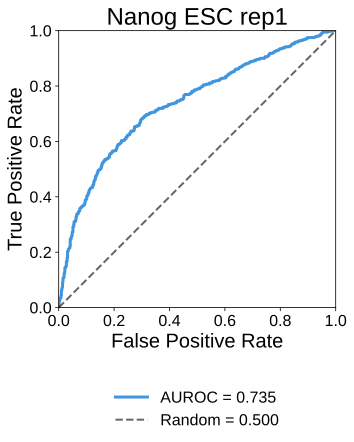

2026-10-26 12:38:51,919 - INFO - maxp pruned


2026-10-26 12:38:51,920 - INFO - LTSH dropped


2026-10-26 12:38:51,920 - INFO - cmap pruned


2026-10-26 12:38:51,921 - INFO - kern dropped


2026-10-26 12:38:51,922 - INFO - post pruned


...

2026-10-26 12:38:52,041 - INFO - glyf pruned


2026-10-26 12:38:52,041 - INFO - GDEF pruned


2026-10-26 12:38:52,041 - INFO - GPOS pruned


2026-10-26 12:38:52,042 - INFO - GSUB pruned


2026-10-26 12:38:52,047 - INFO - name pruned


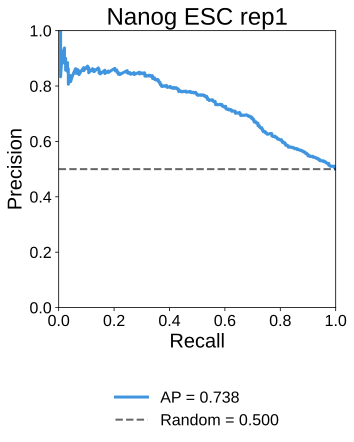

2026-10-26 12:38:52,635 - INFO - maxp pruned


2026-10-26 12:38:52,636 - INFO - LTSH dropped


2026-10-26 12:38:52,636 - INFO - cmap pruned


2026-10-26 12:38:52,637 - INFO - kern dropped


2026-10-26 12:38:52,637 - INFO - post pruned


...

2026-10-26 12:38:52,957 - INFO - glyf pruned


2026-10-26 12:38:52,957 - INFO - GDEF pruned


2026-10-26 12:38:52,958 - INFO - GPOS pruned


2026-10-26 12:38:52,959 - INFO - GSUB pruned


2026-10-26 12:38:52,965 - INFO - name pruned


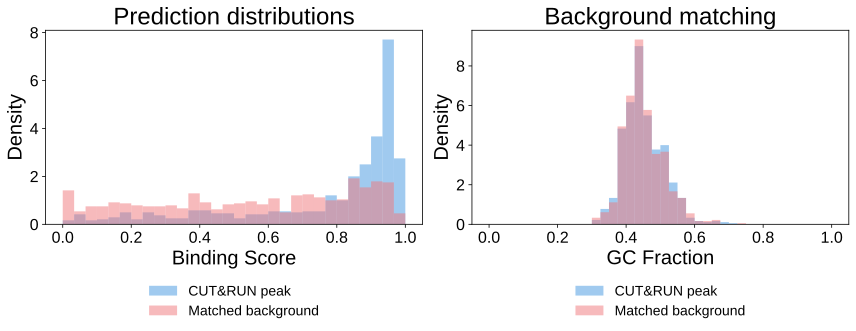

2026-10-26 12:38:53,412 - INFO - maxp pruned


2026-10-26 12:38:53,413 - INFO - LTSH dropped


2026-10-26 12:38:53,413 - INFO - cmap pruned


2026-10-26 12:38:53,414 - INFO - kern dropped


2026-10-26 12:38:53,414 - INFO - post pruned


...

2026-10-26 12:38:53,536 - INFO - glyf pruned


2026-10-26 12:38:53,536 - INFO - GDEF pruned


2026-10-26 12:38:53,538 - INFO - GPOS pruned


2026-10-26 12:38:53,538 - INFO - GSUB pruned


2026-10-26 12:38:53,544 - INFO - name pruned


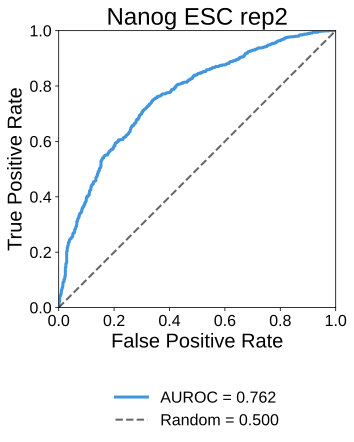

2026-10-26 12:38:53,828 - INFO - maxp pruned


2026-10-26 12:38:53,829 - INFO - LTSH dropped


2026-10-26 12:38:53,829 - INFO - cmap pruned


2026-10-26 12:38:53,830 - INFO - kern dropped


2026-10-26 12:38:53,830 - INFO - post pruned


...

2026-10-26 12:38:53,954 - INFO - glyf pruned


2026-10-26 12:38:53,954 - INFO - GDEF pruned


2026-10-26 12:38:53,955 - INFO - GPOS pruned


2026-10-26 12:38:53,956 - INFO - GSUB pruned


2026-10-26 12:38:53,961 - INFO - name pruned


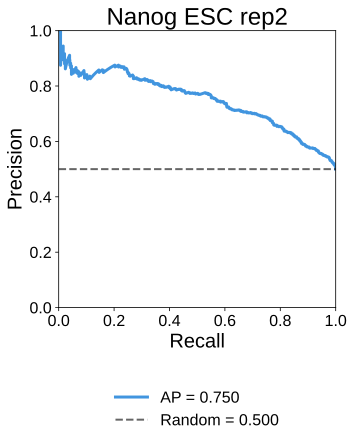

2026-10-26 12:38:54,542 - INFO - maxp pruned


2026-10-26 12:38:54,543 - INFO - LTSH dropped


2026-10-26 12:38:54,543 - INFO - cmap pruned


2026-10-26 12:38:54,544 - INFO - kern dropped


2026-10-26 12:38:54,544 - INFO - post pruned


...

2026-10-26 12:38:54,668 - INFO - glyf pruned


2026-10-26 12:38:54,668 - INFO - GDEF pruned


2026-10-26 12:38:54,669 - INFO - GPOS pruned


2026-10-26 12:38:54,670 - INFO - GSUB pruned


2026-10-26 12:38:54,676 - INFO - name pruned


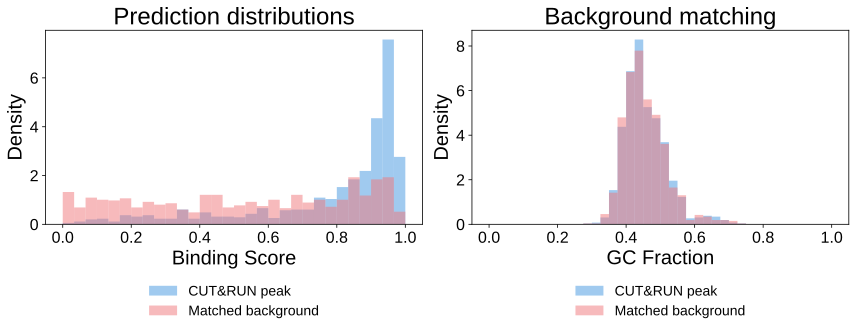

2026-10-26 12:38:55,120 - INFO - maxp pruned


2026-10-26 12:38:55,121 - INFO - LTSH dropped


2026-10-26 12:38:55,121 - INFO - cmap pruned


2026-10-26 12:38:55,121 - INFO - kern dropped


2026-10-26 12:38:55,122 - INFO - post pruned


...

2026-10-26 12:38:55,414 - INFO - glyf pruned


2026-10-26 12:38:55,414 - INFO - GDEF pruned


2026-10-26 12:38:55,414 - INFO - GPOS pruned


2026-10-26 12:38:55,415 - INFO - GSUB pruned


2026-10-26 12:38:55,421 - INFO - name pruned


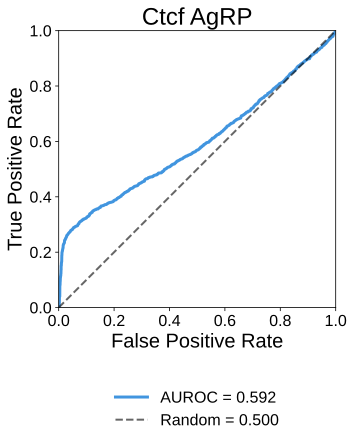

2026-10-26 12:38:55,708 - INFO - maxp pruned


2026-10-26 12:38:55,709 - INFO - LTSH dropped


2026-10-26 12:38:55,709 - INFO - cmap pruned


2026-10-26 12:38:55,710 - INFO - kern dropped


2026-10-26 12:38:55,710 - INFO - post pruned


...

2026-10-26 12:38:55,833 - INFO - glyf pruned


2026-10-26 12:38:55,833 - INFO - GDEF pruned


2026-10-26 12:38:55,833 - INFO - GPOS pruned


2026-10-26 12:38:55,834 - INFO - GSUB pruned


2026-10-26 12:38:55,840 - INFO - name pruned


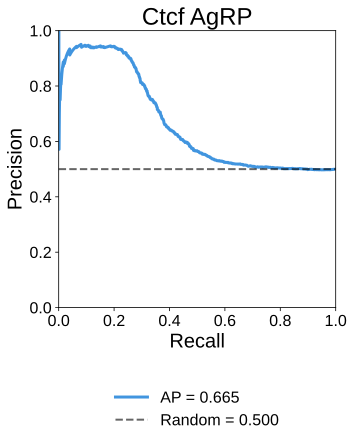

2026-10-26 12:38:56,431 - INFO - maxp pruned


2026-10-26 12:38:56,431 - INFO - LTSH dropped


2026-10-26 12:38:56,432 - INFO - cmap pruned


2026-10-26 12:38:56,432 - INFO - kern dropped


2026-10-26 12:38:56,432 - INFO - post pruned


...

2026-10-26 12:38:56,555 - INFO - glyf pruned


2026-10-26 12:38:56,556 - INFO - GDEF pruned


2026-10-26 12:38:56,556 - INFO - GPOS pruned


2026-10-26 12:38:56,557 - INFO - GSUB pruned


2026-10-26 12:38:56,563 - INFO - name pruned


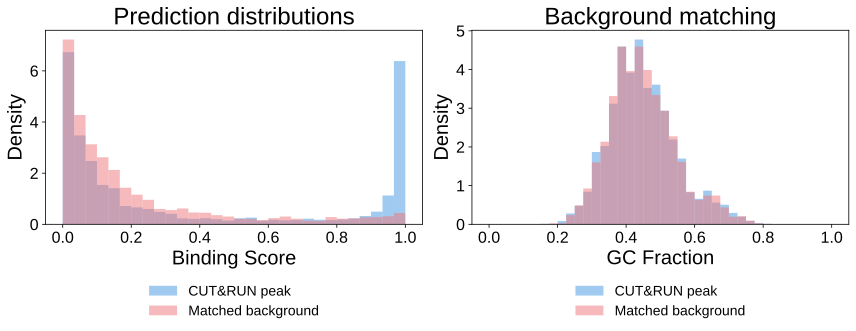

2026-10-26 12:38:57,014 - INFO - maxp pruned


2026-10-26 12:38:57,015 - INFO - LTSH dropped


2026-10-26 12:38:57,015 - INFO - cmap pruned


2026-10-26 12:38:57,015 - INFO - kern dropped


2026-10-26 12:38:57,016 - INFO - post pruned


...

2026-10-26 12:38:57,312 - INFO - glyf pruned


2026-10-26 12:38:57,312 - INFO - GDEF pruned


2026-10-26 12:38:57,313 - INFO - GPOS pruned


2026-10-26 12:38:57,313 - INFO - GSUB pruned


2026-10-26 12:38:57,320 - INFO - name pruned


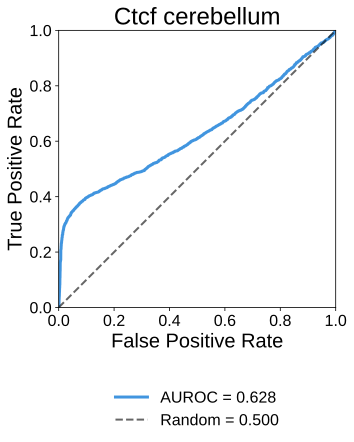

2026-10-26 12:38:57,607 - INFO - maxp pruned


2026-10-26 12:38:57,607 - INFO - LTSH dropped


2026-10-26 12:38:57,608 - INFO - cmap pruned


2026-10-26 12:38:57,608 - INFO - kern dropped


2026-10-26 12:38:57,609 - INFO - post pruned


...

2026-10-26 12:38:57,731 - INFO - glyf pruned


2026-10-26 12:38:57,731 - INFO - GDEF pruned


2026-10-26 12:38:57,732 - INFO - GPOS pruned


2026-10-26 12:38:57,732 - INFO - GSUB pruned


2026-10-26 12:38:57,737 - INFO - name pruned


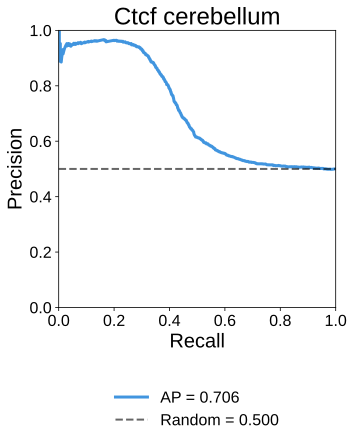

2026-10-26 12:38:58,330 - INFO - maxp pruned


2026-10-26 12:38:58,331 - INFO - LTSH dropped


2026-10-26 12:38:58,331 - INFO - cmap pruned


2026-10-26 12:38:58,332 - INFO - kern dropped


2026-10-26 12:38:58,332 - INFO - post pruned


...

2026-10-26 12:38:58,454 - INFO - glyf pruned


2026-10-26 12:38:58,454 - INFO - GDEF pruned


2026-10-26 12:38:58,454 - INFO - GPOS pruned


2026-10-26 12:38:58,455 - INFO - GSUB pruned


2026-10-26 12:38:58,461 - INFO - name pruned


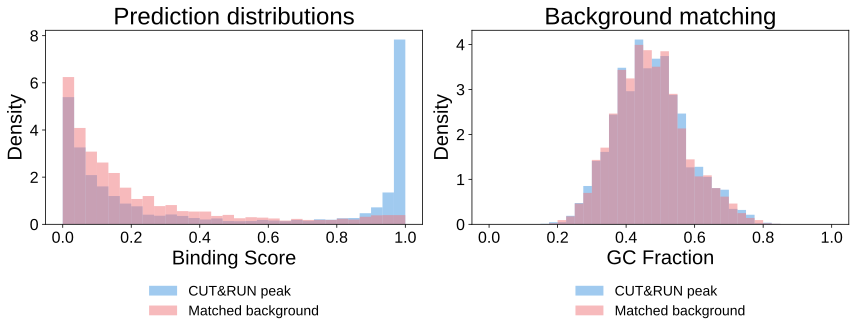

2026-10-26 12:38:58,913 - INFO - maxp pruned


2026-10-26 12:38:58,913 - INFO - LTSH dropped


2026-10-26 12:38:58,914 - INFO - cmap pruned


2026-10-26 12:38:58,914 - INFO - kern dropped


2026-10-26 12:38:58,915 - INFO - post pruned


...

2026-10-26 12:38:59,037 - INFO - glyf pruned


2026-10-26 12:38:59,037 - INFO - GDEF pruned


2026-10-26 12:38:59,038 - INFO - GPOS pruned


2026-10-26 12:38:59,038 - INFO - GSUB pruned


2026-10-26 12:38:59,044 - INFO - name pruned


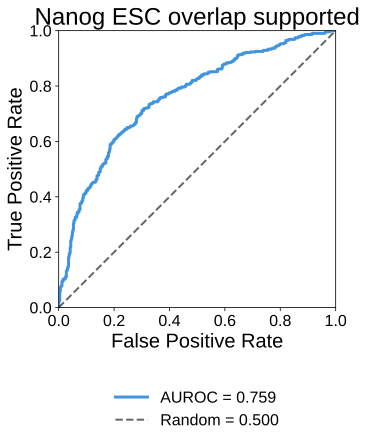

2026-10-26 12:38:59,329 - INFO - maxp pruned


2026-10-26 12:38:59,329 - INFO - LTSH dropped


2026-10-26 12:38:59,330 - INFO - cmap pruned


2026-10-26 12:38:59,330 - INFO - kern dropped


2026-10-26 12:38:59,331 - INFO - post pruned


...

2026-10-26 12:38:59,630 - INFO - glyf pruned


2026-10-26 12:38:59,630 - INFO - GDEF pruned


2026-10-26 12:38:59,631 - INFO - GPOS pruned


2026-10-26 12:38:59,631 - INFO - GSUB pruned


2026-10-26 12:38:59,637 - INFO - name pruned


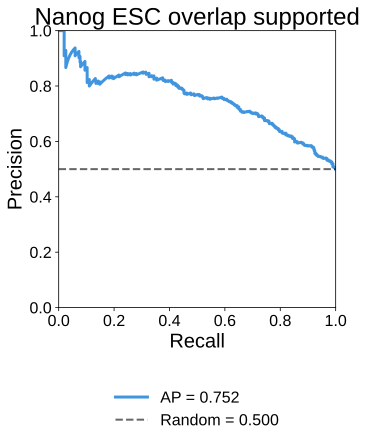

2026-10-26 12:39:00,226 - INFO - maxp pruned


2026-10-26 12:39:00,227 - INFO - LTSH dropped


2026-10-26 12:39:00,227 - INFO - cmap pruned


2026-10-26 12:39:00,227 - INFO - kern dropped


2026-10-26 12:39:00,228 - INFO - post pruned


...

2026-10-26 12:39:00,352 - INFO - glyf pruned


2026-10-26 12:39:00,353 - INFO - GDEF pruned


2026-10-26 12:39:00,353 - INFO - GPOS pruned


2026-10-26 12:39:00,354 - INFO - GSUB pruned


2026-10-26 12:39:00,359 - INFO - name pruned


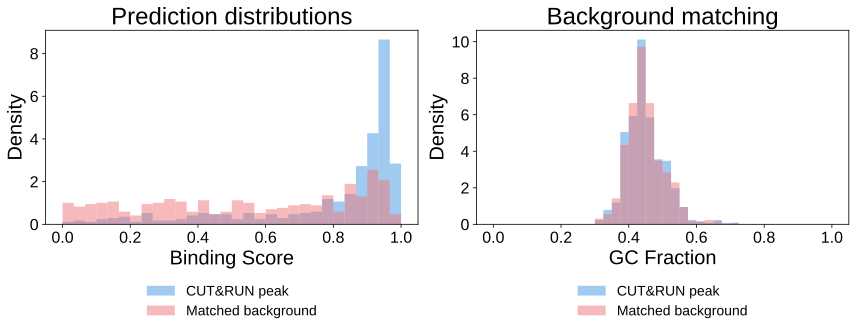

In [8]:
arial_font_path = TETHER_DIR / "fonts" / "Arial.ttf"
if arial_font_path.exists():
    font_manager.fontManager.addfont(str(arial_font_path))
    preferred_font = font_manager.FontProperties(fname=str(arial_font_path)).get_name()
else:
    preferred_font = "DejaVu Sans"
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [preferred_font, "DejaVu Sans"],
    "pdf.fonttype": 42, "svg.fonttype": "none",
    "axes.titlesize": 24, "axes.labelsize": 20, "xtick.labelsize": 16, "ytick.labelsize": 16,
})
model_color = "#4195df"
background_color = "#EF767A"

def save_evaluation_figure(figure, figure_stem):
    for extension in ("png", "pdf", "svg"):
        figure.savefig(evaluation_figure_dir / f"{figure_stem}.{extension}", dpi=300, bbox_inches="tight")

for dataset_name, dataset_prediction_df in prediction_df.groupby("dataset", sort=False):
    labels = dataset_prediction_df["label"].to_numpy()
    scores = dataset_prediction_df["binding_logit"].to_numpy()
    dataset_metrics = metric_summary_df.set_index("dataset").loc[dataset_name]
    roc_figure, roc_axis = plt.subplots(figsize=(6, 5))
    false_positive_rate, true_positive_rate, _ = roc_curve(labels, scores)
    roc_axis.plot(false_positive_rate, true_positive_rate, color=model_color, lw=3,
                  label=f"AUROC = {dataset_metrics['auroc']:.3f}")
    roc_axis.plot([0, 1], [0, 1], color="black", linestyle="--", lw=2, alpha=0.6,
                  label="Random = 0.500")
    roc_axis.set(xlim=(0, 1), ylim=(0, 1), xlabel="False Positive Rate",
                 ylabel="True Positive Rate", title=dataset_name.replace("_", " "))
    roc_axis.set_aspect("equal")
    roc_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=16)
    save_evaluation_figure(roc_figure, f"{dataset_name}_roc")
    plt.show()
    plt.close(roc_figure)

    pr_figure, pr_axis = plt.subplots(figsize=(6, 5))
    precision, recall, _ = precision_recall_curve(labels, scores)
    pr_axis.plot(recall, precision, color=model_color, lw=3,
                 label=f"AP = {dataset_metrics['average_precision']:.3f}")
    pr_axis.axhline(labels.mean(), color="black", linestyle="--", lw=2, alpha=0.6,
                   label=f"Random = {labels.mean():.3f}")
    pr_axis.set(xlim=(0, 1), ylim=(0, 1), xlabel="Recall", ylabel="Precision",
                title=dataset_name.replace("_", " "))
    pr_axis.set_aspect("equal")
    pr_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=16)
    save_evaluation_figure(pr_figure, f"{dataset_name}_precision_recall")
    plt.show()
    plt.close(pr_figure)

    diagnostic_figure, diagnostic_axes = plt.subplots(1, 2, figsize=(12, 5))
    for label, class_name, class_color in (
        (1, "CUT&RUN peak", model_color), (0, "Matched background", background_color),
    ):
        class_rows = dataset_prediction_df.loc[dataset_prediction_df["label"] == label]
        diagnostic_axes[0].hist(class_rows["binding_score"], bins=np.linspace(0, 1, 31),
                                density=True, alpha=0.5, color=class_color, label=class_name)
        diagnostic_axes[1].hist(class_rows["gc_fraction"], bins=np.linspace(0, 1, 41),
                                density=True, alpha=0.5, color=class_color, label=class_name)
    diagnostic_axes[0].set(xlabel="Binding Score", ylabel="Density", title="Prediction distributions")
    diagnostic_axes[1].set(xlabel="GC Fraction", ylabel="Density", title="Background matching")
    diagnostic_axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=14)
    diagnostic_axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False, fontsize=14)
    diagnostic_figure.tight_layout()
    save_evaluation_figure(diagnostic_figure, f"{dataset_name}_diagnostics")
    plt.show()
    plt.close(diagnostic_figure)


## Reproducibility record and interpretation

The run records the checkpoint, input checksums, saved split audit, model input dimensions, matching rules, package versions, compute host, and Slurm job. Prediction tables retain the exact evaluation row order and DNA sequences. Reference FASTA size, modification time, index checksum, and UCSC chromosome-size agreement are recorded; the multi-gigabyte FASTA itself is not re-hashed here.

Interpretation is limited to sequence discrimination for these TFs, assays, chromosomes, and backgrounds. The model receives no cell-state, accessibility, TF-expression, or cofactor measurements. A successful result therefore supports sequence-based enrichment at CUT&RUN peaks; it cannot establish that a site is occupied in every cell type, resolve binding changes over time, or establish genome-wide precision. Background can contain undetected binding, and assay-specific peak calls carry uncertainty. NANOG replicate overlap is a useful consistency check, while the present evaluation does not measure generalization to a TF absent from training.


In [9]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

provenance_input_paths = [
    tf_dna_model_path, evaluation_windows_path,
    *[cutrun_data_dir / item["filename"] for item in cutrun_dataset_definitions
      if item["dataset"] != "Nanog_ESC_overlap_supported"],
    *[tf_embedding_dir / f"{tf_name}_protein_embedding.pt" for tf_name in ("Nanog", "Ctcf")],
    *[tf_dna_input_cache_dir / filename for filename in (
        "train_idx.pt", "val_idx.pt", "test_idx.pt", "edge_peak_idx.pt",
        "peak_id_to_idx.csv", "tf_name_to_idx.csv",
    )],
    cutrun_data_dir / "mm10-blacklist.v2.bed.gz",
    cutrun_data_dir / "mm10.chrom.sizes",
    cutrun_data_dir / "GSE181104_family.soft.gz",
    cutrun_data_dir / "GSE240484_family.soft.gz",
    Path(str(genome_fasta_path) + ".fai"),
]
run_provenance = dict(
    completed_utc=datetime.now(timezone.utc).isoformat(),
    host=socket.gethostname(),
    slurm_job_id=os.environ.get("TF_DNA_CUTRUN_BATCH_JOB_ID", os.environ.get("SLURM_JOB_ID")),
    kernel_environment_slurm_job_id=os.environ.get("SLURM_JOB_ID"),
    checkpoint=str(tf_dna_model_path), device=str(device),
    gpu=torch.cuda.get_device_name() if device.type == "cuda" else None,
    python=platform.python_version(), torch=torch.__version__,
    numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__,
    matplotlib=mpl.__version__, pysam=pysam.__version__,
    chromosomes=EVALUATION_CHROMOSOMES, random_seed=RANDOM_SEED,
    window_length=DNA_WINDOW_LENGTH, gc_tolerance=GC_MATCH_TOLERANCE,
    maximum_matching_attempts=MAXIMUM_MATCH_ATTEMPTS,
    inference_batch_size=INFERENCE_BATCH_SIZE, bootstrap_replicates=BOOTSTRAP_REPLICATES,
    score_orientation="forward genomic", center="valid narrowPeak summit; midpoint fallback",
    genome=dict(path=str(genome_fasta_path), size_bytes=genome_fasta_path.stat().st_size,
                mtime_ns=genome_fasta_path.stat().st_mtime_ns,
                validation="chr1-19 lengths match downloaded UCSC mm10 chromosome sizes"),
    file_sha256={str(path): sha256_file(path) for path in provenance_input_paths},
)
(evaluation_result_dir / "run_provenance.json").write_text(
    json.dumps(run_provenance, indent=2) + "\n",
)

interpretation_lines = [
    "### Observed results",
    "",
    "All results below compare chr18–19 CUT&RUN peaks against 1:1 chromosome- and GC-matched genomic background.",
    "",
    "| Dataset | Positive windows | AUROC (95% paired interval) | AP (95% paired interval) |",
    "|---|---:|---:|---:|",
]
for row in metric_summary_df.itertuples(index=False):
    interpretation_lines.append(
        f"| {row.dataset} | {row.positive_windows:,} | "
        f"{row.auroc:.3f} ({row.auroc_ci_low:.3f}–{row.auroc_ci_high:.3f}) | "
        f"{row.average_precision:.3f} ({row.average_precision_ci_low:.3f}–{row.average_precision_ci_high:.3f}) |"
    )
interpretation_lines += [
    "",
    "Random ranking gives AUROC 0.5 and expected AP 0.5 in this balanced sample. "
    "Assess the effect size, the GC baseline, agreement across chromosomes, and NANOG replicate consistency together. "
    "The intervals describe sampled loci and do not establish biological replicate uncertainty.",
    "",
    f"Predictions and methods records: {evaluation_result_dir}",
    f"Figures: {evaluation_figure_dir}",
]
nanog_primary_result = metric_summary_df.set_index("dataset").loc["Nanog_ESC_overlap_supported"]
interpretation_lines += [
    "",
    f"The overlap-supported NANOG set contains {int(nanog_primary_result['positive_windows']):,} positive windows. "
    f"Its AUROC is {nanog_primary_result['auroc']:.3f} and AP is {nanog_primary_result['average_precision']:.3f}. "
    "These results quantify sequence discrimination for a lineage-restricted TF on the evaluated CUT&RUN peaks.",
    "",
    f"At the fixed score threshold of 0.5, sensitivity is {nanog_primary_result['sensitivity_at_0_5']:.3f} "
    f"and specificity is {nanog_primary_result['specificity_at_0_5']:.3f}. "
    "Ranking performance and threshold performance must therefore be considered separately. "
    "The sampled background does not establish genome-wide precision or cell-specific occupancy.",
]
interpretation_markdown = "\n".join(interpretation_lines)
(evaluation_result_dir / "results_summary.md").write_text(interpretation_markdown + "\n")
display(Markdown(interpretation_markdown))
genome_fasta.close()


### Observed results

All results below compare chr18–19 CUT&RUN peaks against 1:1 chromosome- and GC-matched genomic background.

| Dataset | Positive windows | AUROC (95% paired interval) | AP (95% paired interval) |
|---|---:|---:|---:|
| Nanog_ESC_rep1 | 720 | 0.735 (0.711–0.759) | 0.738 (0.708–0.765) |
| Nanog_ESC_rep2 | 1,042 | 0.762 (0.745–0.782) | 0.750 (0.725–0.774) |
| Ctcf_AgRP | 2,848 | 0.592 (0.578–0.605) | 0.665 (0.652–0.679) |
| Ctcf_cerebellum | 3,377 | 0.628 (0.615–0.641) | 0.706 (0.693–0.719) |
| Nanog_ESC_overlap_supported | 506 | 0.759 (0.733–0.785) | 0.752 (0.720–0.786) |

Random ranking gives AUROC 0.5 and expected AP 0.5 in this balanced sample. Assess the effect size, the GC baseline, agreement across chromosomes, and NANOG replicate consistency together. The intervals describe sampled loci and do not establish biological replicate uncertainty.

Predictions and methods records: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_testing_results/tf_dna_cutrun_epoch21
Figures: /gpfs/Labs/Uzun/SCRIPTS/PROJECTS/2024.SINGLE_CELL_GRN_INFERENCE.MOELLER/TETHER/new_plots/tf_dna_cutrun_epoch21

## Findings from the completed evaluation

The model ranks NANOG CUT&RUN peaks above chromosome- and GC-matched background. For 506 overlap-supported positive windows and the same number of background windows, AUROC is **0.759** (95% paired interval 0.733–0.785) and average precision is **0.752** (0.720–0.786). Both random baselines are 0.5 in this balanced benchmark.

NANOG replicate AUROCs are 0.735 and 0.762; the overlap-supported set gives AUROC 0.747 on chr18 and 0.773 on chr19. GC-only AUROC is 0.498 for the overlap-supported set, supporting that simple residual GC differences do not explain the ranking. The CTCF reference samples give AUROC 0.592 (AgRP) and 0.628 (cerebellum), showing that the strength of separation depends on the evaluated TF and sample.

For overlap-supported NANOG, threshold 0.5 gives sensitivity 0.852 and specificity 0.429. The model therefore shows useful sequence-ranking signal for a lineage-restricted TF, while this fixed threshold calls many background windows positive. Use these results as evidence of sequence discrimination at CUT&RUN peaks; genome-wide precision and cell-specific occupancy remain unmeasured.

All results use chr18–19. The saved-cache audit found zero training or validation peaks on these chromosomes. The run completed on an NVIDIA A100 via Slurm batch job **3927528**, with all nine code cells executed, 16,986 predictions saved, and 15 embedded figures exported as PNG, PDF, and SVG. No Python or R processing ran on a gateway node.
